# Quality Control of AFM Force Spectroscopy Data with Autoencoders

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<a href="https://colab.research.google.com/github/JChonpca/ASAP/blob/AD/tutorials/quality-control/QC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<strong>If using Colab/Kaggle:</strong> You need to uncomment the code in the cell below this one.
You also need to copy the "ae.py" file and "models" folder from the
<a href="https://github.com/DeepTrackAI/ASAP/blob/main/tutorials/quality-control">notebook folder</a> in GitHub to the Colab/Kaggle work directory.
</div>

This notebook provides you with a complete code example that first trains a autoencoder (AE) in the good curves set of AFM force spectroscopy; then uses the reconstruction error to detect bad curves in all spectroscopy.

- **Output 1:** A trained model ready to process experimental data.
- **Output 2:** The threshold for reconstruction loss to identify the good/bad curves.

In [1]:
# Uncomment codes in this cell if using Colab/Kaggle.

# !pip install deeplay ipympl
# from google.colab import output
# output.enable_custom_widget_manager()

## 1. Load the 3T3 Cell Dataset

### 1.1. Download the 3T3 Cell Dataset

Download the 3T3_cell_dataset into the `3T3_cell_dataset` local folder.

This dataset contains AFM force spectroscopy collected using a culture of 3T3 cells (a widely used, immortalized mouse fibroblast cell line derived from Swiss albino mouse embryos).

This dataset contains
- `approach` is a folder with the approach curves, as files `0.npy`, `1.npy`, etc.
- `retraction` is a folder with the retraction curves, paired with the approach curves.
- `label.npy` is the label file for the approach curves: `0` is for bad curves, `1` is for good curves, and `2` is for curves with bi-regime in the indentation part.
- `contact_point.npy` contains the contact points for each curve.

In [2]:
import os

if not os.path.exists("3t3_cell_dataset"):
    os.system("git clone https://github.com/DeepTrackAI/3t3_cell_dataset")

### 1.2. Explore the 3T3 Cell Dataset

Load the 3T3 cell dataset ...

In [3]:
from pathlib import Path
import numpy as np

# Load the approach curves
approach_path = Path.cwd() / "3t3_cell_dataset" / "approach"
approach_files = sorted(approach_path.glob("*.npy"), key=lambda f: int(f.stem))
approach_curves = [np.load(f) for f in approach_files]

# Load the retraction curves
retract_path = Path.cwd() / "3t3_cell_dataset" / "retraction"
retract_files = sorted(retract_path.glob("*.npy"), key=lambda f: int(f.stem))
retract_curves = [np.load(f) for f in retract_files]

# Load the labels
labels = np.load(Path.cwd() / "3t3_cell_dataset" / "label.npy")

# Load the contact points
contactpoints = np.load(Path.cwd() / "3t3_cell_dataset" / "contact_point.npy")


... split the dataset according to label ...

In [4]:
def label_separate(labels: np.ndarray[int], 
                   label: int, 
                   *arrays: np.ndarray,
) -> tuple[list, ...]:
    """Separates data based on a specified label.

    This utility function filters multiple aligned NumPy arrays according
    to a given label. It returns subsets of the input arrays where the
    labels match the specified value.

    Parameters
    ----------
    labels : np.ndarray[int]
        Array of labels used for filtering.
    label : int
        Target label to select.
    *arrays : np.ndarray
        One or more NumPy arrays aligned with `labels`. All arrays must
        have the same length as `labels`.

    Returns
    -------
    tuple[list, ...]
        A tuple where each element corresponds to a filtered version of
        the input arrays, containing only elements whose label matches
        the specified value.

    Examples
    --------
    >>> labels = np.array([0, 0, 1, 1, 1])
    >>> label = 1
    >>> list1 = np.array([1, 2, 3, 4, 5])
    >>> list2 = np.array([5, 4, 3, 2, 1])
    >>> s_l1, s_l2 = label_separate(labels, label, list1, list2)
    >>> s_l1, s_l2
    ([3, 4, 5], [3, 2, 1])

    """

    idx = np.where(labels == label)[0]
    return tuple([[arr[i] for i in idx] for arr in arrays])

# Extract the good curves
(
    good_approach_curves, 
    good_contactpoints,
) = label_separate(
    labels,
    1,
    approach_curves,
    contactpoints,
)

# Extract the bad curves
(
    bad_approach_curves, 
    bad_contactpoints,
) = label_separate(
    labels,
    0,
    approach_curves,
    contactpoints,
)

# Extract the curves of bi-regime
(
    bi_approach_curves, 
    bi_contactpoints,
) = label_separate(
    labels,
    2,
    approach_curves,
    contactpoints,
)

... print the number of approach/retraction curves and labels ...

In [5]:
print(
    f"3T3 cell dataset:\n"
    f"- {len(approach_curves)} approach curves\n"
    f"- {len(retract_curves)} retraction curves\n"
    f"- {len(labels)} labels\n"
    f"- {len(contactpoints)} contact points"
)

3T3 cell dataset:
- 2548 approach curves
- 2548 retraction curves
- 2548 labels
- 2548 contact points


... print the number of good/bad/unknown quality curves for approach part.

In [6]:
print(
    f"Approach curves in dataset:\n"
    f"- {len(good_approach_curves)} good curves\n"
    f"-  {len(bad_approach_curves)} bad curves\n"
    f"-  {len(bi_approach_curves)} curves of bi-regime\n"
)

Approach curves in dataset:
- 1673 good curves
-  575 bad curves
-  300 curves of bi-regime



Finally, you can plot some good curves, highlighting the the contact point ...

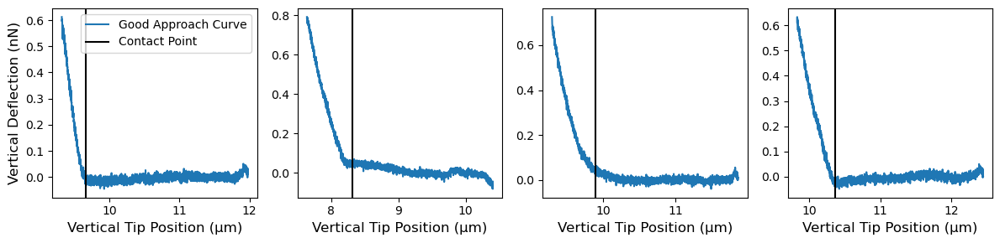

In [7]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 4, figsize=((12, 3)))

for curve_idx, ax in enumerate(axs.ravel()):
    approach_curve = good_approach_curves[curve_idx]
    contactpoint = good_contactpoints[curve_idx]

    ax.plot(approach_curve[:, 0], approach_curve[:, 1], label="Good Approach Curve")

    ax.axvline(contactpoint, c="k", label="Contact Point")

    ax.set_xlabel("Vertical Tip Position (µm)", fontsize=12)
    if curve_idx == 0:
        ax.set_ylabel("Vertical Deflection (nN)", fontsize=12)
        ax.legend()

fig.tight_layout()
plt.show()

... also some bad curves ...

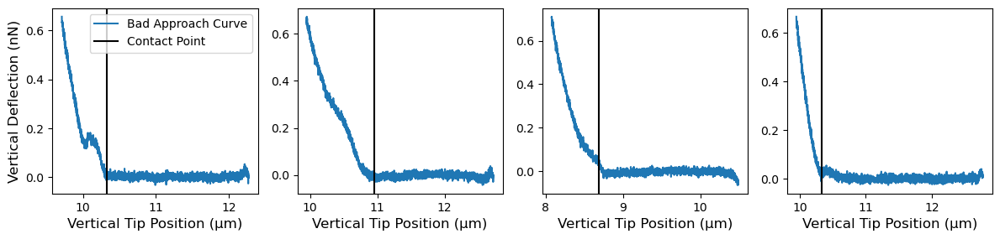

In [8]:
fig, axs = plt.subplots(1, 4, figsize=((12, 3)))

for curve_idx, ax in enumerate(axs.ravel()):
    approach_curve = bad_approach_curves[curve_idx]
    contactpoint = bad_contactpoints[curve_idx]

    ax.plot(approach_curve[:, 0], approach_curve[:, 1], label="Bad Approach Curve")

    ax.axvline(contactpoint, c="k", label="Contact Point")

    ax.set_xlabel("Vertical Tip Position (µm)", fontsize=12)
    if curve_idx == 0:
        ax.set_ylabel("Vertical Deflection (nN)", fontsize=12)
        ax.legend()

fig.tight_layout()
plt.show()

... and some curves of bi-regime.

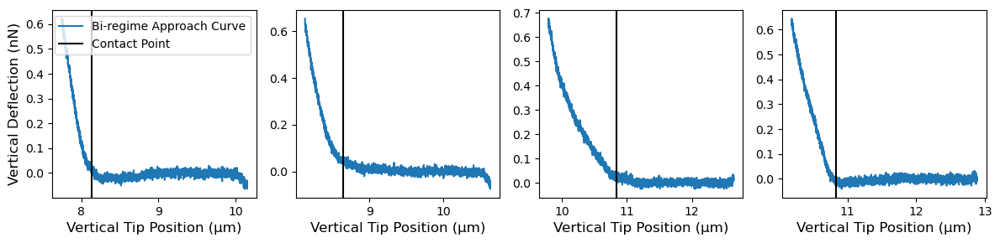

In [9]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 4, figsize=((12, 3)))

for curve_idx, ax in enumerate(axs.ravel()):
    approach_curve = bi_approach_curves[curve_idx]
    contactpoint = bi_contactpoints[curve_idx]

    ax.plot(approach_curve[:, 0], approach_curve[:, 1], label="Bi-regime Approach Curve")

    ax.axvline(contactpoint, c="k", label="Contact Point")

    ax.set_xlabel("Vertical Tip Position (µm)", fontsize=12)
    if curve_idx == 0:
        ax.set_ylabel("Vertical Deflection (nN)", fontsize=12)
        ax.legend()

fig.tight_layout()
plt.show()

## 2. Anomaly Detection of Approach Curves

### 2.1. Data Preprocessing

For the approach curves, resample each approach curve to adjust its length align with the shortest approach curve ...

In [10]:
# Calculate the length of each curve
approach_curve_lengths = [curve.shape[0] for curve in approach_curves]
retract_curve_lengths = [curve.shape[0] for curve in retract_curves]

# Calculate the minimum length of approach curves and retraction curves
min_approach_curve_length = min(approach_curve_lengths)
min_retract_curve_length = min(retract_curve_lengths)

resampled_approach_curves = []
resampled_contactpoints = []
for approach_curve, contactpoint in zip(approach_curves, contactpoints):
    # Resample each approach curve to adjust its length to the shortest one
    steps = np.round(
        np.linspace(0, approach_curve.shape[0] - 1, min_approach_curve_length)
    ).astype(int)
    resampled_approach_curve = approach_curve[steps][:, 1]
    resampled_approach_curves.append(resampled_approach_curve)

    # Determine the contact point for the resampled approach curve
    resampled_approach_position = approach_curve[steps][:, 0]
    resampled_contactpoint = (
        np.abs(resampled_approach_position - contactpoint).argmin()
    )
    resampled_contactpoints.append(resampled_contactpoint)

... and normalize each approach curve betweeen 0 and 1.

In [11]:
# Normalize each approach curve according to its max and min values
norm_approach_curves = []

for resampled_approach_curve in resampled_approach_curves:
    norm_approach_curves.append(
        (resampled_approach_curve - resampled_approach_curve.min())
        / (resampled_approach_curve.max() - resampled_approach_curve.min())
    )

# Normalize each contact point according to min approach length
norm_contact_points = []

for resampled_contactpoint in resampled_contactpoints:
    norm_contact_points.append(
        resampled_contactpoint / min_approach_curve_length
    )

### 2.2. Define the Dataloader

Define the dataset and use it to create the train and test data loaders.

In [12]:
import torch
from torch.utils.data import TensorDataset
import deeplay as dl
from sklearn.model_selection import train_test_split

# Set bi-regime curves as the good one
labels = np.where(labels==2, 1, labels)

# Extract the good curves after normalization
(
    good_norm_approach_curves,
    good_norm_contact_points,
) = label_separate(
    labels,
    1,
    norm_approach_curves,
    norm_contact_points,
)


# Randomly select the train and test data
(
    curves_train,
    curves_test,
    contactpoints_train,
    contactpoints_test,
) = train_test_split(
    good_norm_approach_curves,
    good_norm_contact_points,
    test_size=0.2,
    random_state=577,
)

# Transfer them to Torch.Tensor

train_x = torch.as_tensor(curves_train, dtype=torch.float32)
test_x = torch.as_tensor(curves_test, dtype=torch.float32)


# Instantiate the dataloader for train data
train_dataloader = dl.DataLoader(
    TensorDataset(train_x, train_x),
    batch_size=128, shuffle=True
)

# Instantiate the dataloader for test data
test_dataloader = dl.DataLoader(
    TensorDataset(test_x, test_x),
    batch_size=128, shuffle=True
)

/var/folders/r8/g53kd4_105l87ltvnp_hblc40000gn/T/ipykernel_19396/462599509.py:36: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:256.)
  train_x = torch.as_tensor(curves_train, dtype=torch.float32)


### 2.3. Define the Autoencoder

Import the conditional variational autoencoder module and instantiate a AE with dense layers ...

In [13]:
from ae import AutoEncoder

# Instantiate the cAE model according to the data properties
ae = AutoEncoder(
    input_size=min_approach_curve_length,
    channels=[512, 256, 128, 64],
    reconstruction_loss=torch.nn.MSELoss(reduction="sum"),
    latent_dim=2,
)

# Configure the activated function
ae.encoder.blocks[:].activated(torch.nn.Tanh)
ae.decoder.blocks[:4].activated(torch.nn.Tanh)
ae.decoder.blocks[4].activated(torch.nn.Sigmoid)

# Create the AE application
ae = ae.create()

print(ae)

AutoEncoder(
  (encoder): MultiLayerPerceptron(
    (blocks): LayerList(
      (0): LinearBlock(
        (layer): Linear(in_features=1557, out_features=512, bias=True)
        (activation): Tanh()
      )
      (1): LinearBlock(
        (layer): Linear(in_features=512, out_features=256, bias=True)
        (activation): Tanh()
      )
      (2): LinearBlock(
        (layer): Linear(in_features=256, out_features=128, bias=True)
        (activation): Tanh()
      )
      (3): LinearBlock(
        (layer): Linear(in_features=128, out_features=64, bias=True)
        (activation): Tanh()
      )
      (4): LinearBlock(
        (layer): Linear(in_features=64, out_features=64, bias=True)
        (activation): Tanh()
      )
    )
  )
  (fc_enc): Linear(in_features=64, out_features=2, bias=True)
  (fc_dec): Linear(in_features=2, out_features=64, bias=True)
  (decoder): MultiLayerPerceptron(
    (blocks): LayerList(
      (0): LinearBlock(
        (layer): Linear(in_features=64, out_features=64,

### 2.4. Train the Autoencoder

Instance a trainer with a callback to monitor the validation loss and save the best model ...

In [14]:
from lightning.pytorch.callbacks import ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger

# Save the top-1 model according to the validation loss
checkpoint_callback = ModelCheckpoint(
    monitor="val_total_loss",
    mode="min",
    save_top_k=1,
)

# Set the logger
csv_logger = CSVLogger("logs")

# Instantiate the trainer
ae_trainer = dl.Trainer(
    max_epochs=3_000,
    accelerator="auto",
    callbacks=[checkpoint_callback],
    logger=csv_logger,
)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


... train the AE ...

In [ ]:
ae_trainer.fit(ae, train_dataloader, test_dataloader)

... and load the best model from the callback function.

In [17]:
print(f"The best model is saved at {checkpoint_callback.best_model_path}")

best_ae = AutoEncoder.load_from_checkpoint(
    checkpoint_callback.best_model_path
)

The best model is saved at logs/lightning_logs/version_123/checkpoints/epoch=1473-step=19162.ckpt


You can also load a pretrained model by uncommenting the code below.

In [15]:
# Uncomment if you want to load a pretrained model

# pretraiend_model_path = Path.cwd() / "models" / "epoch=1473-step=19162.ckpt"

# print(f"Loading the model at {pretraiend_model_path}")

# ae.load_state_dict(
#    torch.load(pretraiend_model_path, map_location="cpu")["state_dict"]
# )
# best_ae = ae

Loading the model at /Users/iluvatar/Desktop/Bruker_QC/personalrepo/ASAP/tutorials/quality-control/models/epoch=1473-step=19162.ckpt


### 2.5. Evaluate the Trained AE

Evaluate the trained AE using both the train dataset ...

In [17]:
# Evaluate performance of trained AE on train dataset

_ = ae_trainer.test(best_ae, train_dataloader)

Testing: |                                                                                                    …

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│   test_total_loss_epoch   │     52.32209396362305     │
└───────────────────────────┴───────────────────────────┘

... and on the test dataset.

In [18]:
# Evaluate performance of trained AE on test dataset

_ = ae_trainer.test(best_ae, test_dataloader)

Testing: |                                                                                                    …

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│   test_total_loss_epoch   │    58.105804443359375     │
└───────────────────────────┴───────────────────────────┘

### 2.6. Reconstruct and Denoise the Approach Curves

The trained AE can be used to reconstruct and denoise the approach curves.

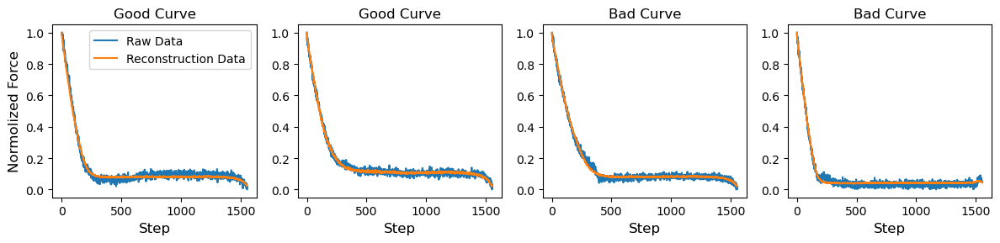

In [19]:
# Put the model under eval mode
best_ae.eval()

# Construct the dataset
norm_approach_curves = torch.as_tensor(
    norm_approach_curves, 
    dtype=torch.float32
)

all_dataloader = dl.DataLoader(
    TensorDataset(norm_approach_curves, norm_approach_curves),
    batch_size=len(norm_approach_curves),
    shuffle=False
)

# Collect the original curves and corresponding reconstruction
with torch.no_grad():
    for indx, batch in enumerate(all_dataloader):
        x_list, y_list = batch
        y_hat_list, _, = best_ae(x_list)

# Transfer them into Numpy array
y_list = x_list.numpy()
y_hat_list = y_hat_list.numpy()

# Extract the good curves and corresponding reconstruction
(
    good_curves,
    good_reconstructions,
) = label_separate(
    labels,
    1,
    y_list,
    y_hat_list,
)

# Extract the good curves and corresponding reconstruction
(
    bad_curves,
    bad_reconstructions,
) = label_separate(
    labels,
    0,
    y_list,
    y_hat_list,
)

# Transfer them into Numpy array
(
    good_curves, 
    good_reconstructions, 
    bad_curves, 
    bad_reconstructions
) = (
    np.array(good_curves),
    np.array(good_reconstructions),
    np.array(bad_curves),
    np.array(bad_reconstructions),
)


# Plot the comparison between the reconstruction and the originals
fig, axs = plt.subplots(1, 4, figsize=((12, 3)))

for curve_idx, ax in enumerate(axs.ravel()):
    if curve_idx < 2:
        # good curves part
        data_apporach_plot_raw = good_curves[curve_idx][::-1]
        data_apporach_plot_reconstruct = good_reconstructions[curve_idx][::-1]
        data_label = "Good Curve"
    else:
        # bad curves part
        data_apporach_plot_raw = bad_curves[curve_idx][::-1]
        data_apporach_plot_reconstruct = bad_reconstructions[curve_idx][::-1]
        data_label = "Bad Curve"
    
    ax.plot(data_apporach_plot_raw, label="Raw Data")
    ax.plot(data_apporach_plot_reconstruct, label="Reconstruction Data")

    ax.set_title(data_label)
    ax.set_xlabel("Step", fontsize=12)
    
    if curve_idx == 0:
        ax.set_ylabel("Normolized Force", fontsize=12)
        ax.legend()

fig.tight_layout()
plt.show()

### 2.7. Detecting Anomalies from the Reconstruction Error

Determine the threshold for reconstrution error based on good curves ...

In [20]:
# Calculate the reconstruction errors
diff = abs(good_curves - good_reconstructions).mean(axis=1)

# 95% quantile value as threshold
threshold_loss = np.quantile(diff, 0.95)
print(f" The threshold value is {threshold_loss}")

 The threshold value is 0.016980048269033432


... plot the histogram of reconstrution errors, highlighting the threshold.

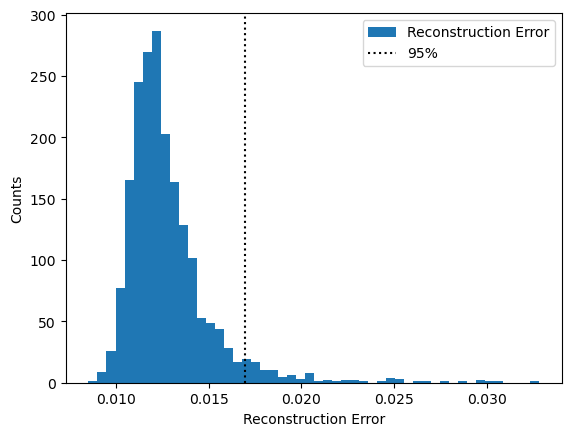

In [21]:
plt.hist(diff, bins=50, label="Reconstruction Error")
plt.axvline(x=threshold_loss, color="k", linestyle=":", label="95%")
plt.xlabel("Reconstruction Error")
plt.ylabel("Counts")
plt.legend()

Apply the threshold value to whole dataset ...

In [22]:
all_diff = abs(y_list - y_hat_list).mean(axis=1)
all_pred = np.where(all_diff>threshold_loss, 0, 1)

... and evaulate performance with accuracy, precision, and recall.

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Assign the unknown quality as bad curves  
labels = np.where(labels == -1, 0, labels)

# Calculate the metrics
print(f"Accuracy = {accuracy_score(labels, all_pred):.3f}  "
          f"Precision = {precision_score(labels, all_pred):.3f}  "
          f"Recall = {recall_score(labels, all_pred):.3f}  "
          f"F1 = {f1_score(labels, all_pred):.3f}")

Accuracy = 0.841  Precision = 0.860  Recall = 0.950  F1 = 0.902


### 2.8. Classification Discrimination Performance

The receiver Operating Characteristic (ROC) curve and precision-recall curves are used to evaluate the classification performance.

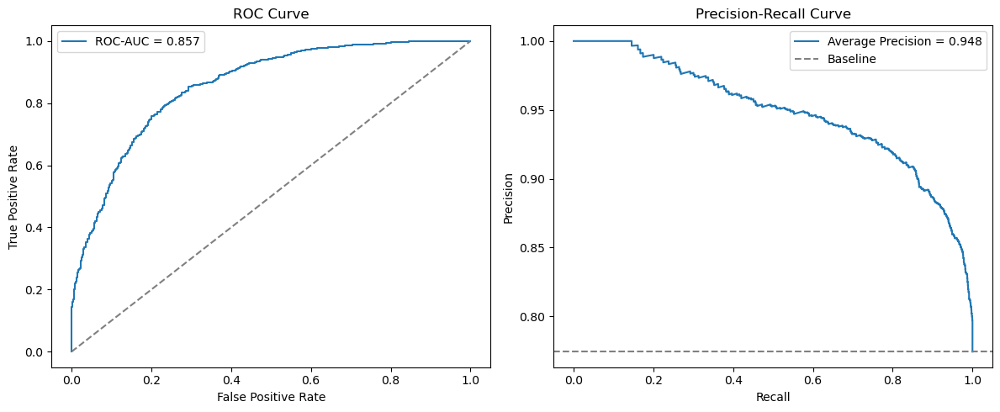

ROC-AUC = 0.857
Average Precision = 0.948


In [24]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
    average_precision_score,
    roc_auc_score
)

# Ground truth
y_true = np.where(labels == 2, 1, labels)

# Continuous reconstruction error as anomaly score
y_score = -all_diff

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

# PR curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_true, y_score
)
ap = average_precision_score(y_true, y_score)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

# PR
axes[1].plot(recall, precision, label=f"Average Precision = {ap:.3f}")
axes[1].axhline(
    y_true.mean(),
    linestyle="--",
    color="gray",
    label="Baseline"
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"ROC-AUC = {roc_auc:.3f}")
print(f"Average Precision = {ap:.3f}")

### 2.9. Data Quality Changes with Reconstruction Loss

Play with weight to see how reconstruction loss changes with data quality.

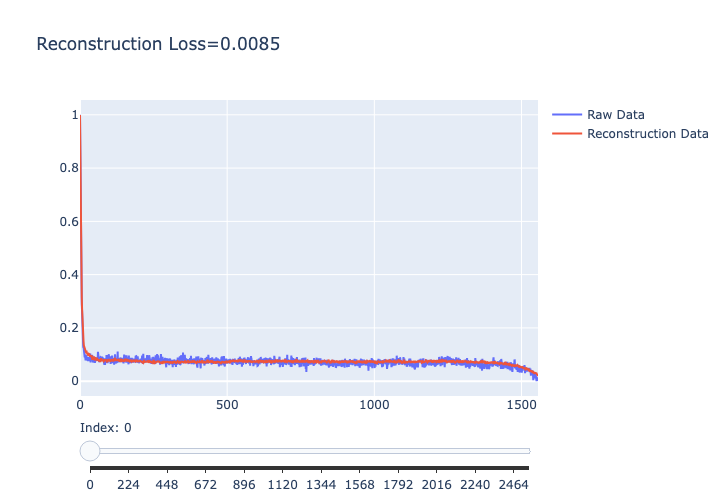

In [25]:
import numpy as np
import plotly.graph_objects as go

# Sort by reconstruction loss
sorted_idx = np.argsort(all_diff)
y_list_sort = [y_list[i][::-1] for i in sorted_idx]
y_hat_list_sort = [y_hat_list[i][::-1] for i in sorted_idx]
diff_sort = [all_diff[i] for i in sorted_idx]

# Frames Construction
frames = []
for i in range(len(y_list_sort)):
    frames.append(
        go.Frame(
            data=[
                go.Scatter(y=y_list_sort[i], mode="lines", name="Raw Data"),
                go.Scatter(y=y_hat_list_sort[i], mode="lines", name="Reconstruction Data"),
            ],
            name=str(i),
            layout=go.Layout(title=f"Reconstruction Loss={diff_sort[i]:.4f}"),
        )
    )

# Initial Picture
fig = go.Figure(
    data=[
        go.Scatter(y=y_list_sort[0], mode="lines", name="Raw Data"),
        go.Scatter(y=y_hat_list_sort[0], mode="lines", name="Reconstruction Data"),
    ],
    layout=go.Layout(title=f"Reconstruction Loss={diff_sort[0]:.4f}"),
    frames=frames,
)

# Slider
sliders = [
    {
        "steps": [
            {
                "args": [
                    [str(i)],
                    {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"},
                ],
                "label": f"{i}",
                "method": "animate",
            }
            for i in range(len(y_list_sort))
        ],
        "currentvalue": {"prefix": "Index: "},
    }
]

fig.update_layout(sliders=sliders, autosize=False, width=700, height=500)

fig.show()